# **Projectwork 1: Exploring Deep Learning Techniques for Basic Point Cloud Analysis in Environmental Monitoring**

**Specialication:** Digital Environment  
**Authors:** Florian Klaver, Nicola Noger  
**Supervisor:** Martin Schüle  
**Submission Deadline:** 22.05.2025


---
## **Introduction**

**Here we shortly describe the project. Not too much detail rest in report**

### **Features**
| Field               | Description |
|---------------------|------------|
| **X**              | X coordinate (East-West) in projected coordinate system. |
| **Y**              | Y coordinate (North-South) in projected coordinate system. |
| **Z**              | Elevation (height) above a reference surface. |
| **intensity**      | Strength of the laser return signal. |
| **return_number**  | Order of the return (e.g., first, second, etc.). |
| **number_of_returns** | Total number of returns for a given laser pulse. |
| **scan_direction_flag** | Indicates scanning direction (0 = forward, 1 = backward). |
| **edge_of_flight_line** | Marks if a point is at the edge of a flight path. |
| **synthetic**      | Flag indicating if the point was generated artificially. |
| **key_point**      | Flag for important points (e.g., survey control points). |
| **withheld**       | Flag for points that should be ignored (e.g., noise). |
| **scan_angle_rank** | Angle of the laser scan (-90° to +90°). |
| **user_data**      | Custom field for additional information. |
| **point_source_id** | Identifier for the source of the point (e.g., flight line). |
| **gps_time**       | Timestamp of when the point was captured. |
| **classification** | Category of the point. <br> <br> **1**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Unclassified  <br> **2**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Ground  <br> **3**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Vegetation  <br> **6**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Building  <br> **9**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Water  <br>**17**&nbsp;&nbsp;&nbsp;= Bridge  |




---
## **Setup**

In [43]:
# All imports

import os
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import laspy
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from scipy.spatial import cKDTree
from torch.utils.data import DataLoader, TensorDataset


# Enable vectorized graphics
%config InlineBackend.figure_formats = ["svg"]

---
## **Preprocessing**

#### Load the data

In [2]:
path_flo = "C:/Users/flori/Desktop/pa-1_data/zurich_1.las"
# path_nicola = 

las = laspy.read(path_flo)

# List all available attributes in the LAS file
print("Available attributes in LAS file:")
for spec in las.point_format.dimension_names:
    print("-", spec)


# total number of points
n_points = len(las.points)
print("\nTotal number of points:", n_points)

print(las.header)
print(las.points)

Available attributes in LAS file:
- X
- Y
- Z
- intensity
- return_number
- number_of_returns
- scan_direction_flag
- edge_of_flight_line
- classification
- synthetic
- key_point
- withheld
- scan_angle_rank
- user_data
- point_source_id
- gps_time

Total number of points: 12902017
<LasHeader(1.2, <PointFormat(1, 0 bytes of extra dims)>)>
<ScaleAwarePointRecord(fmt: <PointFormat(1, 0 bytes of extra dims)>, len: 12902017, point size: 28)>


In [ ]:
# Inforamtion for transforming the data into a pandas dataframe
print(type(las.x)) 
print(type(las.x[0])) 

<class 'laspy.point.dims.ScaledArrayView'>
<class 'numpy.float64'>


In [4]:
# Create a pandas DataFrame with the LAS data for initial data exploration
df = pd.DataFrame({
    "X": np.array(las.x), 
    "Y": np.array(las.y),
    "Z": np.array(las.z),
    "intensity": np.array(las.intensity),
    "return_number": np.array(las.return_number),
    "number_of_returns": np.array(las.number_of_returns),
    "scan_direction_flag": np.array(las.scan_direction_flag),
    "edge_of_flight_line": np.array(las.edge_of_flight_line),
    "synthetic": np.array(las.synthetic),
    "key_point": np.array(las.key_point),
    "withheld": np.array(las.withheld),
    "user_data": np.array(las.user_data),
    "point_source_id": np.array(las.point_source_id),
    "scan_angle_rank": np.array(las.scan_angle_rank),
    "gps_time": np.array(las.gps_time),
    "classification": np.array(las.classification)
})


# get a first impression of the data
print(df.shape)
display(df.info())
display(df.describe())
display(df.head())
print("\nClassification values:")
display(df["classification"].value_counts())

(12902017, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12902017 entries, 0 to 12902016
Data columns (total 16 columns):
 #   Column               Dtype  
---  ------               -----  
 0   X                    float64
 1   Y                    float64
 2   Z                    float64
 3   intensity            uint16 
 4   return_number        uint8  
 5   number_of_returns    uint8  
 6   scan_direction_flag  uint8  
 7   edge_of_flight_line  uint8  
 8   synthetic            uint8  
 9   key_point            uint8  
 10  withheld             uint8  
 11  user_data            uint8  
 12  point_source_id      uint16 
 13  scan_angle_rank      int8   
 14  gps_time             float64
 15  classification       uint8  
dtypes: float64(4), int8(1), uint16(2), uint8(9)
memory usage: 566.0 MB


None

,X,Y,Z,intensity,return_number,number_of_returns,scan_direction_flag,edge_of_flight_line,synthetic,key_point,withheld,user_data,point_source_id,scan_angle_rank,gps_time,classification
count,1.290202e+07,1.290202e+07,1.290202e+07,1.290202e+07,1.290202e+07,1.290202e+07,12902017.0,12902017.0,12902017.0,12902017.0,12902017.0,1.290202e+07,1.290202e+07,1.290202e+07,1.290202e+07,1.290202e+07
mean,2.683532e+06,1.247508e+06,4.311112e+02,1.346394e+02,1.374864e+00,1.750828e+00,0.0,0.0,0.0,0.0,0.0,5.225372e+01,1.226129e+02,-8.729442e-01,2.051168e+08,3.921719e+00
std,2.977153e+02,2.757434e+02,1.662515e+01,2.602035e+02,7.983605e-01,1.181962e+00,0.0,0.0,0.0,0.0,0.0,8.472675e+00,9.829875e-01,1.678507e+01,6.876755e+02,2.147887e+00
min,2.683000e+06,1.247000e+06,3.891200e+02,5.000000e+00,1.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,0.0,1.700000e+01,1.210000e+02,-3.000000e+01,2.051151e+08,1.000000e+00
25%,2.683251e+06,1.247295e+06,4.194700e+02,5.200000e+01,1.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,0.0,4.800000e+01,1.220000e+02,-1.400000e+01,2.051165e+08,2.000000e+00
50%,2.683573e+06,1.247499e+06,4.291200e+02,1.110000e+02,1.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,0.0,5.000000e+01,1.230000e+02,-3.000000e+00,2.051165e+08,3.000000e+00
75%,2.683791e+06,1.247744e+06,4.396300e+02,1.770000e+02,1.000000e+00,2.000000e+00,0.0,0.0,0.0,0.0,0.0,5.300000e+01,1.230000e+02,1.300000e+01,2.051173e+08,6.000000e+00
max,2.684000e+06,1.248000e+06,5.158300e+02,6.553400e+04,7.000000e+00,7.000000e+00,0.0,0.0,0.0,0.0,0.0,2.400000e+02,1.250000e+02,3.000000e+01,2.051179e+08,1.700000e+01


,X,Y,Z,intensity,return_number,number_of_returns,scan_direction_flag,edge_of_flight_line,synthetic,key_point,withheld,user_data,point_source_id,scan_angle_rank,gps_time,classification
0,2683033.91,1247000.0,433.53,71,1,1,0,0,0,0,0,47,125,29,2.051151e+08,6
1,2683074.91,1247000.0,426.62,73,1,2,0,0,0,0,0,46,125,29,2.051151e+08,6
2,2683086.29,1247000.0,433.13,114,1,1,0,0,0,0,0,49,125,29,2.051151e+08,6
3,2683135.96,1247000.0,417.98,106,2,2,0,0,0,0,0,67,125,28,2.051151e+08,6
4,2683139.50,1247000.0,431.08,183,1,1,0,0,0,0,0,50,125,28,2.051151e+08,6



Classification values:


classification
6     5217866
2     4469036
3     2829680
1      291256
17      90614
9        3565
Name: count, dtype: int64

In [15]:
# check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# check for duplicates
print("\nDuplicates:")
print(df.duplicated().sum())


Missing values:
X                      0
Y                      0
Z                      0
intensity              0
return_number          0
number_of_returns      0
scan_direction_flag    0
edge_of_flight_line    0
synthetic              0
key_point              0
withheld               0
user_data              0
point_source_id        0
scan_angle_rank        0
gps_time               0
classification         0
dtype: int64

Duplicates:
0


In [ ]:
# check for the number of unique values in each column
print(df.nunique())

X                       100000
Y                       100000
Z                        10348
intensity                 1485
return_number                7
number_of_returns            7
scan_direction_flag          1
edge_of_flight_line          1
synthetic                    1
key_point                    1
withheld                     1
user_data                  213
point_source_id              5
scan_angle_rank             61
gps_time               9881020
classification               6
dtype: int64


In [27]:
# Columns with only one unique value can already be dropped sice they do not add any information to the model
df = df.loc[:, df.nunique() > 1]
print("\nDataFrame after dropping columns with only one unique value:")
display(df.info())

# There are other features such as user_data or point_source_id that most likely do not add any information to the model.
# We will keep them for now and confirm this assumption later in the analysis.


DataFrame after dropping columns with only one unique value:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12902017 entries, 0 to 12902016
Data columns (total 11 columns):
 #   Column             Dtype  
---  ------             -----  
 0   X                  float64
 1   Y                  float64
 2   Z                  float64
 3   intensity          uint16 
 4   return_number      uint8  
 5   number_of_returns  uint8  
 6   user_data          uint8  
 7   point_source_id    uint16 
 8   scan_angle_rank    int8   
 9   gps_time           float64
 10  classification     uint8  
dtypes: float64(4), int8(1), uint16(2), uint8(4)
memory usage: 504.5 MB


None

In [28]:
features = df.drop(columns=["classification"])

---
## **Explorative Data Analysis**

#### Class distribution

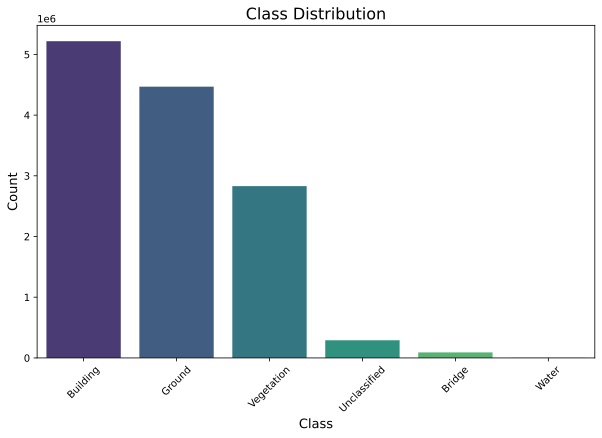

In [29]:
class_labels = {
    1: "Unclassified",
    2: "Ground",
    3: "Vegetation",
    6: "Building",
    9: "Water",
    17: "Bridge"
}

class_counts = df["classification"].value_counts()
class_labels_mapped = class_counts.index.map(class_labels).fillna("Other")

# Plot the class distribution
plt.figure(figsize=(10, 6))
sns.barplot(x=class_labels_mapped, y=class_counts.values, hue=class_labels_mapped, palette="viridis")
plt.title("Class Distribution", fontsize=16)
plt.xlabel("Class", fontsize=13)
plt.ylabel("Count", fontsize=13)
plt.xticks(rotation=45)
plt.show()

#### Histogram

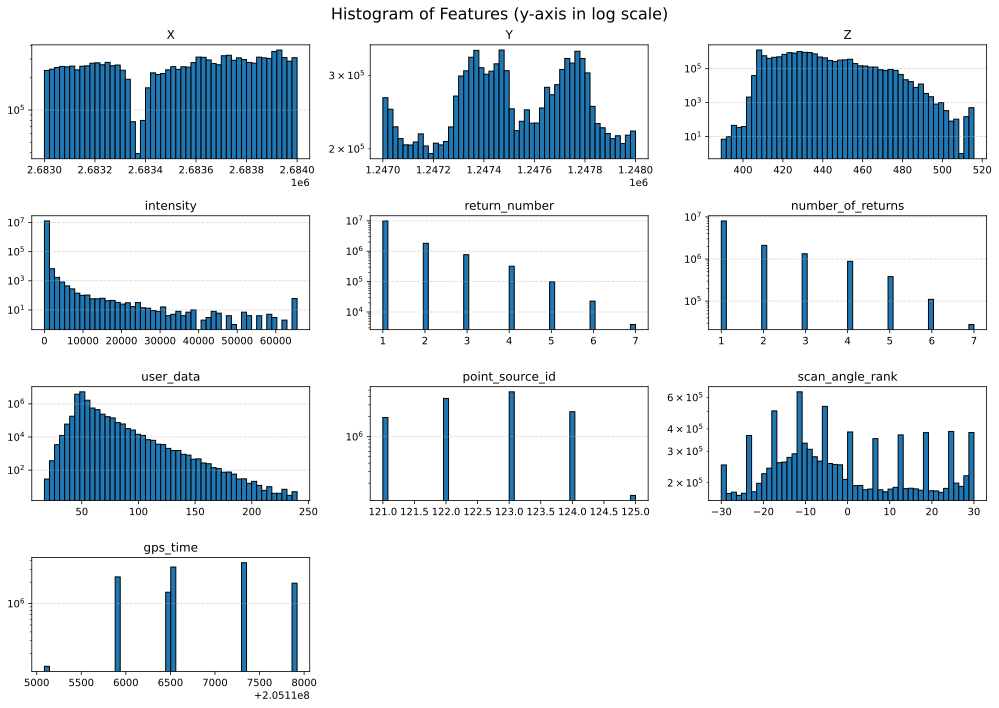

In [55]:
axes = features.hist(figsize=(14, 10), bins=50, edgecolor='black')  
plt.suptitle("Histogram of Features (y-axis in log scale)", fontsize=16)

# Convert axes to a flat list (in case of multiple rows)
axes = axes.flatten()

# Disable x-axis grid and enable y-axis grid
for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.grid(False, axis='x')
    ax.set_yscale("log")

# Set y-axis to log scale for intensity  
#intensity_index = features.columns.get_loc("intensity")
#axes[intensity_index].set_yscale("log")


plt.tight_layout()
plt.show()

#### Boxplot

#### Correlation-matrix

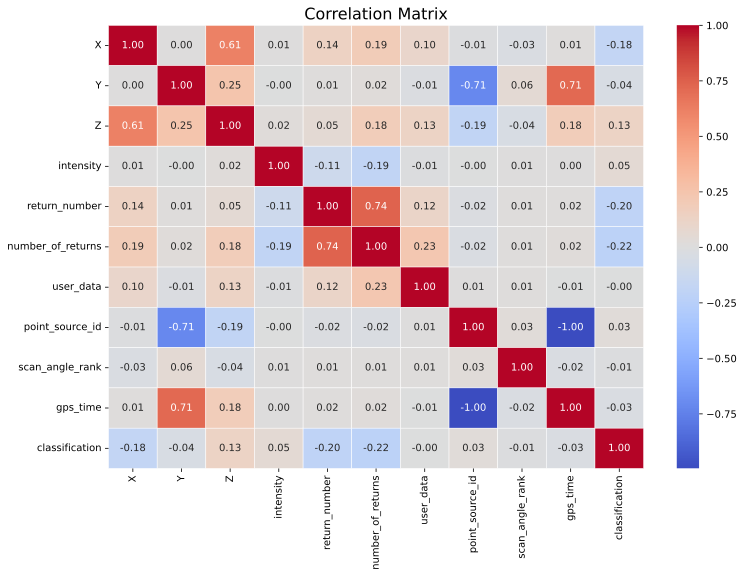

classification       1.000000
Z                    0.130653
intensity            0.054763
point_source_id      0.029739
user_data           -0.002862
scan_angle_rank     -0.012396
gps_time            -0.028846
Y                   -0.043548
X                   -0.180146
return_number       -0.204861
number_of_returns   -0.220738
Name: classification, dtype: float64

In [42]:
corr = df.corr()
f, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", annot=True, linewidths=0.5, fmt=".2f", ax=ax)
plt.title("Correlation Matrix", fontsize=16)
plt.show()

# print correlation values for classification
display(corr['classification'].sort_values(ascending=False))

---
## **Feature Engineering**

Check feature importance with random forest model

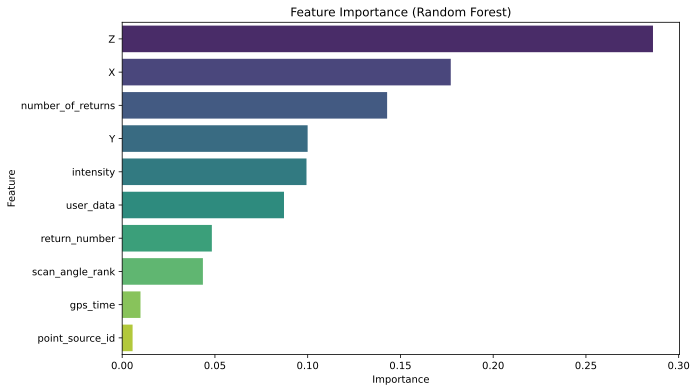

In [44]:
# define features and target
X = df.drop(columns=['classification'])
y = df['classification']

# train random forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

# extract feature importances
importances = rf.feature_importances_
feature_names = X.columns
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# sort the features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importance (Random Forest)')
plt.show()

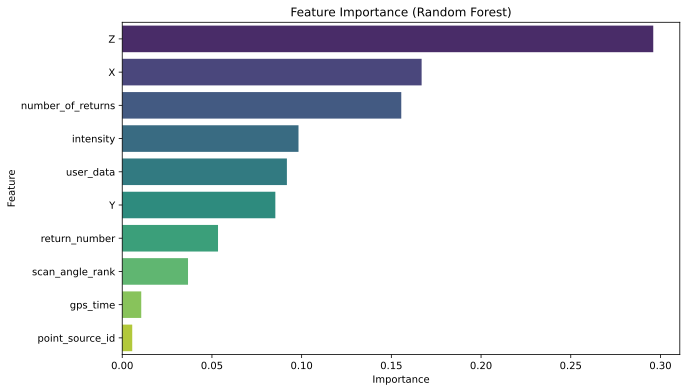

In [ ]:
# faster version of the random forest

# define features and target
X = df.drop(columns=['classification'])
y = df['classification']

# train random forest
rf = RandomForestClassifier(n_estimators= 80, max_depth= 20, n_jobs=-1, random_state=42)
X_sample, _, y_sample, _ = train_test_split(X, y, train_size=8000000, stratify=y, random_state=42)
rf.fit(X_sample, y_sample)

# extract feature importances
importances = rf.feature_importances_
feature_names = X.columns
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# sort the features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importance (Random Forest)')
plt.show()

---
## **Model Developement**

#### First Basic PyTorch model

In [56]:
# === Compute ground height (approximate lowest Z value) ===
ground_height = np.min(las.z)

# === Extract Features (Adding Local Height Variance) ===
# Build a KDTree for nearest-neighbor search
xyz = np.vstack((las.x, las.y, las.z)).T
tree = cKDTree(xyz)

# Compute local height variance for each point
_, idxs = tree.query(xyz, k=10)  # Find 10 nearest neighbors
local_height_var = np.var(las.z[idxs], axis=1)

X = np.vstack((
    las.x, 
    las.y, 
    las.z, 
    las.intensity, 
    las.return_number,  
    las.number_of_returns, 
    las.z - ground_height,  # Height normalization
    las.scan_angle_rank,
    local_height_var  # New feature: local height variance
)).T.astype(np.float32)

# === Extract classification labels and create a mapping ===
unique_labels = np.unique(las.classification)
label_map = {label: idx for idx, label in enumerate(unique_labels)}
y = np.array([label_map[label] for label in las.classification]).astype(np.int64)

# === Take a larger random sample (e.g., 12 million points) ===
sample_indices = np.random.choice(X.shape[0], size=1200000, replace=False)
X = X[sample_indices]
y = y[sample_indices]

# === Normalize Features ===
scaler = StandardScaler()
X = scaler.fit_transform(X)

# === Convert to PyTorch tensors and split data ===
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

# === Compute Class Weights for Imbalanced Data ===
class_counts = np.bincount(y_train.numpy())  # Get count of each class
class_weights = 1.0 / class_counts  # Inverse frequency
class_weights = torch.tensor(class_weights, dtype=torch.float32)

# === Define Improved Neural Network with Residual Connections ===
class PointCloudNet(nn.Module):
    def __init__(self, input_size, num_classes):
        super(PointCloudNet, self).__init__()
        self.fc1 = nn.Linear(input_size, 128)
        self.bn1 = nn.BatchNorm1d(128)
        
        self.fc2 = nn.Linear(128, 256)
        self.bn2 = nn.BatchNorm1d(256)
        
        self.fc3 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        
        self.fc4 = nn.Linear(128, num_classes)
        
        self.leaky_relu = nn.LeakyReLU(0.1)  # LeakyReLU instead of ReLU
        self.dropout = nn.Dropout(p=0.2)  # Lowered dropout for better learning

    def forward(self, x):
        x1 = self.leaky_relu(self.bn1(self.fc1(x)))
        x2 = self.leaky_relu(self.bn2(self.fc2(x1)))
        x3 = self.leaky_relu(self.bn3(self.fc3(x2))) + x1  # Residual connection
        x3 = self.dropout(x3)  # Dropout applied before final layer
        return self.fc4(x3)

# Initialize model
input_size = X_train.shape[1]
num_classes = len(unique_labels)
model = PointCloudNet(input_size, num_classes)

# === Define Loss, Optimizer, and Learning Rate Scheduler ===
criterion = nn.CrossEntropyLoss(weight=class_weights)  # Weighted loss
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

# Dynamic learning rate adjustment
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=5, factor=0.5)

# === Train the Model (100 Epochs) ===
num_epochs = 100
batch_size = 512  # Reduced for better generalization

for epoch in range(num_epochs):
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    
    scheduler.step(loss)  # Reduce LR on plateau
    
    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}")

# === Evaluate Model ===
with torch.no_grad():
    test_outputs = model(X_test)
    predicted = torch.argmax(test_outputs, axis=1)
    accuracy = (predicted == y_test).float().mean()
    print(f"Test Accuracy: {accuracy:.4f}")

Epoch [5/100], Loss: 1.4649
Epoch [10/100], Loss: 1.2004
Epoch [15/100], Loss: 1.0719
Epoch [20/100], Loss: 0.9874
Epoch [25/100], Loss: 0.9183
Epoch [30/100], Loss: 0.8630
Epoch [35/100], Loss: 0.8093
Epoch [40/100], Loss: 0.7716
Epoch [45/100], Loss: 0.7372
Epoch [50/100], Loss: 0.7016
Epoch [55/100], Loss: 0.6756
Epoch [60/100], Loss: 0.6479
Epoch [65/100], Loss: 0.6274
Epoch [70/100], Loss: 0.6087
Epoch [75/100], Loss: 0.5929
Epoch [80/100], Loss: 0.5695
Epoch [85/100], Loss: 0.5575
Epoch [90/100], Loss: 0.5436
Epoch [95/100], Loss: 0.5264
Epoch [100/100], Loss: 0.5151
Test Accuracy: 0.8041


---
## **Model Deployment**